# UE01 – Neuronales Netzwerk mit MNIST

**Name:** Marcus Strohmer  
**Ziel:** Ein einfaches neuronales Netz zur Klassifikation handgeschriebener Ziffern trainieren und testen.

In [23]:
# NumPy verarbeitet Zahlenarrays, Pandas Tabellen und Matplotlib Diagramme.
# TensorFlow/Keras stellt Datenlader und neuronale Netze bereit.
# Sequential ordnet Schichten nacheinander an. Dense ist eine vollständig verbundene Schicht.
# Input beschreibt die Eingabeform. to_categorical erzeugt One-Hot-Labels.
# Die Seeds setzen Zufallszahlengeneratoren auf einen festen Startwert.
# Das erleichtert Vergleiche. Je nach Hardware können trotzdem Abweichungen auftreten.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow-Version:", tf.__version__)
#seed ist ein Zufallsstartwert Zufall wird beispielsweise verwendet, um die anfänglichen Gewichte des Netzes festzulegen und die Trainingsbilder zu mischen.

TensorFlow-Version: 2.22.0-rc0


## 1.1 MNIST-Dataset laden und untersuchen

In [24]:
# load_data liefert zwei Paare aus Bildern (x) und richtigen Antworten (y).
# Training verwendet 60.000 Beispiele zum Anpassen der Gewichte.
# Die 10.000 Testbeispiele dienen in diesem Notebook der anschließenden Bewertung.
# x_train_original.shape ist (60000, 28, 28): Bilder, Pixelzeilen, Pixelspalten.
# y_train_original.shape ist (60000,): eine Ziffer pro Bild.
# shape[0] liefert die Bildanzahl. dtype beschreibt den Datentyp der einzelnen Werte.
# [0] wählt das erste Beispiel. Bild und Label mit demselben Index gehören zusammen.
# min() und max() prüfen den Wertebereich der Pixel. Ursprünglich liegt er bei 0 bis 255.

(x_train_original, y_train_original), (x_test_original, y_test_original) = tf.keras.datasets.mnist.load_data()

print("x_train:", x_train_original.shape, x_train_original.dtype)
print("y_train:", y_train_original.shape, y_train_original.dtype)
print("x_test: ", x_test_original.shape, x_test_original.dtype)
print("y_test: ", y_test_original.shape, y_test_original.dtype)
print("Shape eines Bildes:", x_train_original[0].shape)
print("Pixelbereich:", x_train_original.min(), "bis", x_train_original.max())
print("Label des ersten Bildes:", y_train_original[0])
x_train_original[0]

x_train: (60000, 28, 28) uint8
y_train: (60000,) uint8
x_test:  (10000, 28, 28) uint8
y_test:  (10000,) uint8
Shape eines Bildes: (28, 28)
Pixelbereich: 0 bis 255
Label des ersten Bildes: 5


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

Das Trainingsset enthält 60.000 Bilder und das Testset 10.000 Bilder. Jedes Bild besteht aus 28 × 28 = 784 Pixeln. Die Pixelwerte liegen zwischen 0 und 255.

## 1.2 Trainingsbilder als `pd.DataFrame`

Ein DataFrame erwartet eine zweidimensionale Struktur. Deshalb wird jedes 28×28-Bild zu einer Zeile mit 784 Spalten umgeformt.

In [25]:
# reshape ordnet die 28*28 Pixel jedes Bildes zu einer Zeile mit 784 Werten an.
# shape[0] liefert hier 60000. reshape(-1, 784) würde dieselbe Form ergeben.
# pd.DataFrame macht aus dem zweidimensionalen Array eine Tabelle.
# Eine Tabellenzeile entspricht einem Bild, eine Spalte einer Pixelposition.
# head() zeigt die ersten fünf Bildzeilen. x_train_flat ist die umgeformte Darstellung.

x_train_flat = x_train_original.reshape(x_train_original.shape[0], 28 * 28)
df_train = pd.DataFrame(x_train_flat)
print("Shape des DataFrames:", df_train.shape)
df_train.head()

Shape des DataFrames: (60000, 784)


,0,1,2,3,4,5,6,7,8,9,...,774,775,776,777,778,779,780,781,782,783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 1.3 Erstes Trainingsbild darstellen

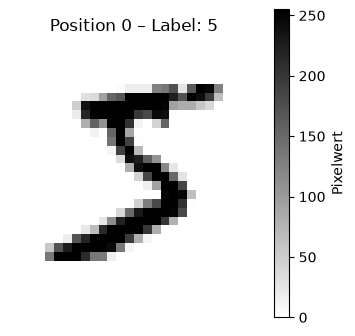

In [28]:
# figure legt die Darstellungsgröße in Zoll fest.
# imshow zeichnet das erste 28x28-Pixelraster. gray_r verwendet umgekehrte Graustufen.
# Der f-String setzt das Label in den Titel ein. colorbar zeigt die Farbzuordnung.
# axis("off") blendet die Achsen aus, show() zeigt die Grafik an.

plt.figure(figsize=(4, 4))
plt.imshow(x_train_original[0], cmap="gray_r")
plt.title(f"Position 0 – Label: {y_train_original[0]}")
plt.colorbar(label="Pixelwert")
plt.axis("off")
plt.show()

Das erste Bild stellt tatsächlich die Ziffer **5** dar; das zugehörige Label `y_train_original[0]` ist ebenfalls 5.

## 1.4 Warum braucht der Output-Layer 10 Knoten?

MNIST enthält zehn mögliche Klassen, nämlich die Ziffern **0 bis 9**. Für jede Klasse wird ein Ausgabeknoten benötigt. Die Softmax-Aktivierung erzeugt für diese zehn Knoten Wahrscheinlichkeiten, deren Summe 1 ergibt. Die Klasse mit der höchsten Wahrscheinlichkeit ist die Vorhersage des Modells.

## Daten für das Modell vorbereiten

Die Bilder werden zu Vektoren mit 784 Werten umgeformt und auf den Bereich 0 bis 1 normalisiert. Die ganzzahligen Labels werden one-hot-kodiert.

In [31]:
# reshape(-1, 784) berechnet die Bildanzahl automatisch und legt 784 Werte pro Bild fest.
# astype("float32") wandelt die Pixel in Gleitkommazahlen um.
# Die Division durch 255.0 normalisiert jeden Pixel auf 0 bis 1.
# Die gleichen Verarbeitungsschritte gelten für Trainings- und Testbilder.
# to_categorical(..., num_classes=10) erzeugt zehn Werte pro Label.
# Aus der Ziffer 5 wird [0,0,0,0,0,1,0,0,0,0].
# Danach sind die Formen x_train=(60000,784) und y_train=(60000,10).
# Die ursprünglichen Bilder und Ziffern liegen weiter in den Variablen mit _original.

x_train = x_train_original.reshape(-1, 784).astype("float32") / 255.0
x_test = x_test_original.reshape(-1, 784).astype("float32") / 255.0

y_train = to_categorical(y_train_original, num_classes=10)
y_test = to_categorical(y_test_original, num_classes=10)

print("x_train:", x_train.shape)
print("x_test: ", x_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)
print("Erstes Label vor One-hot:", y_train_original[10])
print("Erstes Label nach One-hot:", y_train[10])

x_train: (60000, 784)
x_test:  (10000, 784)
y_train: (60000, 10)
y_test:  (10000, 10)
Erstes Label vor One-hot: 3
Erstes Label nach One-hot: [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


## 1.5 Modell implementieren und kompilieren

In [32]:
# Sequential erhält hier eine Liste von Schichten. model.add(...) wäre eine andere Schreibweise.
#Sequential ist ein Keras-Modell, bei dem die Schichten der Reihe nach durchlaufen werden. Die Ausgabe einer Schicht wird zur Eingabe der nächsten.
# Input(shape=(784,)) erwartet 784 Pixelwerte pro Bild. Die Bildanzahl ist variabel.
# Jedes der 64 Dense-Neuronen erhält alle 784 Eingaben.
# Ein Neuron berechnet z = Summe(Eingang * Gewicht) + Bias.
# ReLU berechnet max(0,z). Diese Nichtlinearität ermöglicht komplexe Zusammenhänge.
# Die Ausgabeschicht hat zehn Neuronen für die Ziffern 0 bis 9.
# Softmax wandelt ihre Ergebnisse in zehn Wahrscheinlichkeiten mit Summe 1 um.
# compile legt das Trainingsverfahren fest. RMSprop aktualisiert Gewichte und Bias.
# categorical_crossentropy bewertet die Wahrscheinlichkeit der richtigen Klasse.
# Dieser Loss passt hier zu den One-Hot-Labels.
# accuracy misst den Anteil der Bilder, bei denen die höchste Wahrscheinlichkeit zur richtigen Ziffer gehört.
# summary zeigt Formen und Parameter. Eine Dense-Schicht hat Eingänge*Neuronen + Neuronen Parameter.
# Hier sind das 784*64+64=50240 und 64*10+10=650, insgesamt 50890.
# None in einer Ausgabeform steht für die variable Anzahl der gemeinsam verarbeiteten Bilder.

model = Sequential([
    Input(shape=(784,)),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax"),
])

model.compile(
    optimizer="rmsprop",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

#784x64 + 64 Bias Werte
#Neuron 1: alle 784 Pixel × eigene Gewichte + eigener Bias → ReLU → ein Wert
#Neuron 2: alle 784 Pixel × eigene Gewichte + eigener Bias → ReLU → ein Wert
#…
#Neuron 64: alle 784 Pixel × eigene Gewichte + eigener Bias → ReLU → ein Wert

#ReLU und die Sprungfunktion sind zwei unterschiedliche Aktivierungsfunktionen.
#ReLU berechnet max(0, z). Negative Werte werden zu 0, positive Werte werden direkt weitergegeben.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

Das Modell besitzt 50.890 trainierbare Parameter: 784×64 + 64 im Hidden-Layer und 64×10 + 10 im Output-Layer.

## 1.6 Modell trainieren

In [33]:
# fit startet das Lernen mit Bildern und zugehörigen One-Hot-Labels.
# Eine Epoche umfasst alle 60000 Trainingsbilder. Hier gibt es fünf Epochen.
# Ein Batch enthält bis zu 128 Bilder. Nach jedem Batch erfolgt eine Gewichtsaktualisierung.
# 60000 / 128 ergibt 468 volle Batches und einen Restbatch mit 96 Bildern: 469 Schritte je Epoche.

# Vorwärtsrechnung erzeugt Vorhersagen, der Loss bewertet sie.
# 5 zu 90% 3 zu 20% wenn es tatsächlich 3 ist Verlustsfunktion loss fällt höher aus

# Backpropagation berechnet Gradienten, RMSprop verwendet sie zur Parameteränderung. – berechnen, wie die Parameter den Fehler beeinflussen
# jetzt wird in die andere Richtung gerechnet, Gewichte werden angepasst, es wird geschaut wird der loss kleiner wenn ich bestimmte Gewichte verändere
#               -Eine positive Ableitung bedeutet, dass eine kleine Erhöhung des Gewichts den Loss erhöht. Zum Senken des Loss sollte das Gewicht kleiner werden.
#               -Eine negative Ableitung bedeutet, dass eine kleine Erhöhung des Gewichts den Loss senkt. Das Gewicht sollte größer werden.
#RMSprop – die Gewichte tatsächlich anpassen
# verbose=1 zeigt den Fortschritt an.
# Das zurückgegebene History-Objekt speichert Kennzahlen für jede Epoche.

history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=128,
    verbose=1,
)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8933 - loss: 0.3923
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9424 - loss: 0.1994
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9550 - loss: 0.1536
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9627 - loss: 0.1266
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9684 - loss: 0.1083


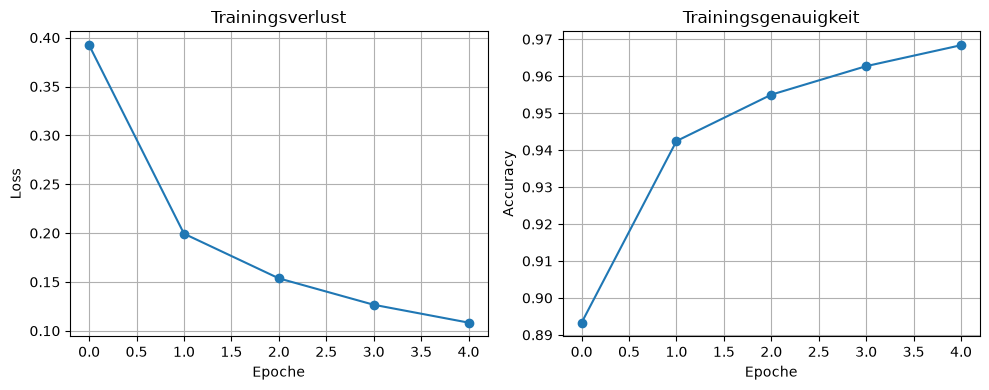

In [34]:
# subplot(1,2,1) und subplot(1,2,2) erzeugen zwei Diagramme nebeneinander.
# history.history ist ein Dictionary. Die Schlüssel loss und accuracy liefern Listen mit einem Wert je Epoche.
# plot ohne eigene x-Werte verwendet die Indizes 0 bis 4 für die fünf Epochen.
# Die Beschriftung Epoche ist deshalb hier nullbasiert.
# marker="o" zeichnet Punkte. grid aktiviert das Raster, tight_layout ordnet die Diagramme an.
# Diese Kurven beschreiben die Leistung während des Trainings.

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], marker="o")
plt.title("Trainingsverlust")
plt.xlabel("Epoche")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], marker="o")
plt.title("Trainingsgenauigkeit")
plt.xlabel("Epoche")
plt.ylabel("Accuracy")
plt.grid(True)

plt.tight_layout()
plt.show()

## 1.7 Modell mit den Testdaten evaluieren

In [35]:
# evaluate berechnet Loss und Accuracy auf den Testbildern mit den trainierten Gewichten.
# Die Rückgabereihenfolge folgt hier loss und der beim compile angegebenen Metrik accuracy.
# Die zwei Ergebnisse werden in test_loss und test_accuracy gespeichert.
# :.4f formatiert vier Nachkommastellen. :.2% stellt den Wert als Prozent mit zwei Nachkommastellen dar.

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)
print(f"Test-Loss: {test_loss:.4f}") #:.4f zeigt die Zahl mit vier Nachkommastellen.
print(f"Test-Accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})") #:.2% zeigt sie als Prozentwert mit zwei Nachkommastellen. Dafür wird sie zur Anzeige mit 100 multipliziert und um % ergänzt.
#Während evaluate() werden die Gewichte nicht angepasst. Das unterscheidet es von fit(), bei dem das Modell anhand der Fehler weiterlernt.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9662 - loss: 0.1123
Test-Loss: 0.1123
Test-Accuracy: 0.9662 (96.62%)


Wahrscheinlichkeiten: [0.000e+00 0.000e+00 0.000e+00 7.000e-04 0.000e+00 0.000e+00 0.000e+00
 9.992e-01 0.000e+00 0.000e+00]
Vorhergesagte Ziffer: 7
Tatsächliche Ziffer: 7


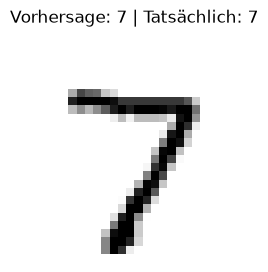

In [38]:
# x_test[:1] enthält das erste Testbild als Batch der Form (1,784).
# Der Slice erhält die Batch-Achse. x_test[0] allein hätte die Form (784,).
# predict liefert hier ein Array der Form (1,10) mit zehn Wahrscheinlichkeiten.
# y_pred[0] wählt die zehn Werte des ersten Bildes aus.
# argmax liefert die Position des größten Werts. Diese Position entspricht der vorhergesagten Ziffer.
# int wandelt sie in eine Python-Ganzzahl um. round rundet nur die angezeigten Wahrscheinlichkeiten.
# Zum Zeichnen wird das ursprüngliche 28x28-Bild verwendet.
# y_test_original[0] liefert die richtige Ziffer zum Vergleich.

y_pred = model.predict(x_test[:1], verbose=0)
predicted_digit = int(np.argmax(y_pred[0]))

print("Wahrscheinlichkeiten:", np.round(y_pred[0], 4))
print("Vorhergesagte Ziffer:", predicted_digit)
print("Tatsächliche Ziffer:", int(y_test_original[0]))

plt.figure(figsize=(3, 3))
plt.imshow(x_test_original[0], cmap="gray_r")
plt.title(f"Vorhersage: {predicted_digit} | Tatsächlich: {y_test_original[0]}")
plt.axis("off")
plt.show()

## Fazit

Das neuronale Netz kann die handgeschriebenen Ziffern des MNIST-Testdatensatzes mit hoher Genauigkeit klassifizieren. Durch das Umformen auf 784 Eingabewerte kann jedes Bild von Dense-Layern verarbeitet werden; die zehn Softmax-Ausgänge repräsentieren die Ziffern 0 bis 9.